# Finding planets in starlight

A two-branch 1D CNN (a simplified AstroNet, Shallue & Vanderburg 2018) that looks at a folded NASA Kepler
light curve and decides whether the dip is a real planet transit or a false positive.

**By** Adarsh Kundu and Aarnav Piparsania.

**How to run:** *Run All*. The slow step (downloading ~1,700 light curves) is cached on disk and skipped
unless you switch it on in the next cell. Results are written to `results/` and figures to `figures/`.

In [1]:
import io, json, os, shutil, tempfile, urllib.request, warnings
from concurrent.futures import ThreadPoolExecutor, as_completed

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import GroupShuffleSplit

warnings.filterwarnings("ignore")

# The two slow steps are cached on disk. Set these to True to redo them from scratch.
REBUILD_DATASET = False   # ~40 min: download ~1,700 light curves from NASA and make the views

DATA, RAW, RESULTS, FIGURES = "data", "data/raw", "results", "figures"
for folder in (DATA, RAW, RESULTS, FIGURES):
    os.makedirs(folder, exist_ok=True)

BLUE, ORANGE, AQUA, GREY, INK = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984", "#2b2b2a"
plt.rcParams.update({
    "font.size": 9, "axes.edgecolor": GREY, "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK, "ytick.color": INK, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e1",
    "grid.linewidth": 0.6, "legend.frameon": False, "figure.dpi": 110,
})


def save(fig, name=None):
    """Show a figure here, and save it to figures/ when the report uses it."""
    fig.tight_layout()
    if name:
        fig.savefig(os.path.join(FIGURES, name), dpi=200)
    plt.show()

## 1. The KOI catalogue

The NASA Exoplanet Archive's cumulative table has one row per *Kepler Object of Interest* (a repeating dip
that Kepler's software flagged). `koi_disposition` is our label. `koi_score` and `koi_pdisposition` are
NASA's own vetting verdicts: the model never sees them, we only use them as a benchmark at the end.

In [2]:
KOI_COLUMNS = [
    "kepid", "kepoi_name", "koi_disposition",            # label
    "koi_pdisposition", "koi_score",                     # held out: NASA's own verdict
    "koi_period", "koi_time0bk", "koi_duration", "koi_depth",
    "koi_prad", "koi_model_snr", "koi_steff", "koi_srad", "koi_smass",
    "koi_fpflag_nt", "koi_fpflag_ss", "koi_fpflag_co", "koi_fpflag_ec",
]
TAP_URL = ("https://exoplanetarchive.ipac.caltech.edu/TAP/sync?query="
           "select+{cols}+from+cumulative&format=csv")


def download_koi_table():
    path = os.path.join(DATA, "koi_table.csv")
    if os.path.exists(path):
        return pd.read_csv(path)
    print("Downloading KOI cumulative table ...")
    url = TAP_URL.format(cols=",".join(KOI_COLUMNS))
    with urllib.request.urlopen(url, timeout=120) as r:
        df = pd.read_csv(io.BytesIO(r.read()))
    df.to_csv(path, index=False)
    return df


koi = download_koi_table()
koi.koi_disposition.value_counts()

koi_disposition
FALSE POSITIVE    4839
CONFIRMED         2748
CANDIDATE         1977
Name: count, dtype: int64

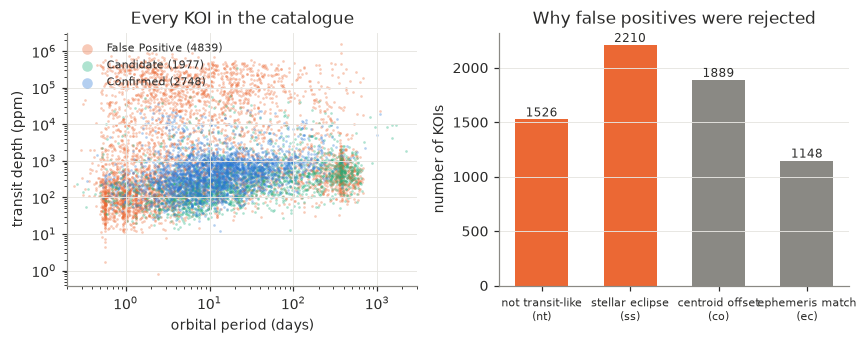

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(8, 3.2))
for disp, c in [("FALSE POSITIVE", ORANGE), ("CANDIDATE", AQUA), ("CONFIRMED", BLUE)]:
    k = koi[koi.koi_disposition == disp]
    ax[0].scatter(k.koi_period, k.koi_depth, s=3, alpha=0.35, color=c,
                  label=f"{disp.title()} ({len(k)})", linewidths=0)
ax[0].set(xscale="log", yscale="log", xlim=(0.2, 3000), xlabel="orbital period (days)",
          ylabel="transit depth (ppm)", title="Every KOI in the catalogue")
ax[0].legend(markerscale=4, fontsize=7, loc="upper left")

fp = koi[koi.koi_disposition == "FALSE POSITIVE"]
flags = {"not transit-like\n(nt)": fp.koi_fpflag_nt.sum(),
         "stellar eclipse\n(ss)": fp.koi_fpflag_ss.sum(),
         "centroid offset\n(co)": fp.koi_fpflag_co.sum(),
         "ephemeris match\n(ec)": fp.koi_fpflag_ec.sum()}
ax[1].bar(list(flags), list(flags.values()), color=[ORANGE, ORANGE, GREY, GREY], width=0.6)
for i, v in enumerate(flags.values()):
    ax[1].text(i, v, f"{int(v)}", ha="center", va="bottom", fontsize=8)
ax[1].set(title="Why false positives were rejected", ylabel="number of KOIs")
ax[1].tick_params(axis="x", labelsize=7)
ax[1].grid(axis="x", visible=False)
save(fig, "dataset.png")

### Choosing our sample

A balanced set of confirmed planets and false positives, plus some CANDIDATEs that we only predict on at the
end. The table flags *why* something is a false positive:

| flag | meaning | visible in the light curve? |
|---|---|---|
| `nt` | not transit-like | yes |
| `ss` | stellar eclipse (eclipsing binary) | yes |
| `co` | centroid offset: the dip is on a neighbouring star | no, needs pixel data |
| `ec` | ephemeris match: contamination from another star | no, needs a catalogue |

Our model only sees the light curve, so we train only on false positives with `nt` or `ss` set.

In [4]:
PER_CLASS = 800      # planets and false positives each
N_CANDIDATES = 200   # unconfirmed KOIs we only predict on at the end


def choose_kois(koi, per_class, n_candidates, seed=0):
    rng = np.random.default_rng(seed)
    koi = koi.dropna(subset=["koi_period", "koi_time0bk", "koi_duration"])

    planets = koi[koi.koi_disposition == "CONFIRMED"]
    fps = koi[(koi.koi_disposition == "FALSE POSITIVE") &
              ((koi.koi_fpflag_nt == 1) | (koi.koi_fpflag_ss == 1))]
    cands = koi[koi.koi_disposition == "CANDIDATE"]

    def pick(df, n):
        return df.iloc[rng.permutation(len(df))[:n]]

    chosen = pd.concat([pick(planets, per_class), pick(fps, per_class), pick(cands, n_candidates)])
    return chosen.reset_index(drop=True)

## 2. Downloading a light curve

For every star we download all long-cadence (29.4-minute) quarters from MAST with Lightkurve. We keep the
**PDCSAP** flux, from which Kepler's pipeline has already removed most spacecraft effects. Each star is cached
in `data/raw/` as a small `.npz`, so an interrupted run can just be restarted.

In [5]:
def download_quarters(kepid):
    """All long-cadence PDCSAP quarters for one star: a list of (time, flux, quality) arrays."""
    path = os.path.join(RAW, f"{kepid}.npz")
    if os.path.exists(path):
        try:
            return list(np.load(path, allow_pickle=True)["quarters"])
        except Exception:
            os.remove(path)                  # half-written file from an interrupted run

    import lightkurve as lk
    search = lk.search_lightcurve(f"KIC {kepid}", mission="Kepler", author="Kepler", cadence="long")
    tmp = tempfile.mkdtemp()                 # FITS files are big; we keep only the arrays
    try:
        lcs = search.download_all(quality_bitmask="default", download_dir=tmp)
        quarters = [(np.asarray(lc.time.value, float), np.asarray(lc["pdcsap_flux"].value, float),
                     np.asarray(lc.quality.value)) for lc in lcs]
    finally:
        shutil.rmtree(tmp, ignore_errors=True)
    np.savez_compressed(path + ".tmp.npz", quarters=np.array(quarters, dtype=object))
    os.replace(path + ".tmp.npz", path)      # write-then-rename so a crash can't leave junk
    return quarters

## 3. Cleaning a light curve

Times are in days (Kepler's BKJD). Durations come in hours from the KOI table, so we convert them first.

1. **Stitch quarters.** Each quarter the star lands on a different CCD with a slightly different sensitivity,
   so we divide each quarter by its own median. We also drop flagged and missing points.
2. **Detrend.** Divide out the star's slow variability with a running median. In-transit points are hidden
   from the median so it can't eat into the dip, and the window is at least 3 transit durations long.
3. **Clip outliers, upward only.** A point far *below* the baseline might be the transit itself.

In [6]:
def stitch_quarters(quarters):
    all_t, all_f = [], []
    for t, f, q in quarters:
        t, f, q = np.asarray(t, float), np.asarray(f, float), np.asarray(q)
        good = (q == 0) & np.isfinite(t) & np.isfinite(f)   # drop flagged cadences
        if good.sum() < 100:
            continue
        all_t.append(t[good])
        all_f.append(f[good] / np.median(f[good]))          # quarter-wise normalisation
    if not all_t:
        return None, None
    t, f = np.concatenate(all_t), np.concatenate(all_f)
    order = np.argsort(t)
    return t[order], f[order]


def phase_time(t, period, t0):
    """Time from the nearest transit centre, in days, in [-P/2, P/2). Every transit lands on 0."""
    return (t - t0 + 0.5 * period) % period - 0.5 * period


def detrend(t, f, period, t0, duration_days):
    in_transit = np.abs(phase_time(t, period, t0)) < 1.5 * duration_days
    window_days = max(1.0, 3 * duration_days)

    f_masked = f.copy()
    f_masked[in_transit] = np.nan            # hide the transits from the running median
    series = pd.Series(f_masked, index=pd.to_timedelta(t, unit="D"))
    trend = series.rolling(pd.Timedelta(days=window_days), center=True, min_periods=10).median()
    trend = trend.interpolate(limit_direction="both").to_numpy()
    return f / trend


def clip_outliers(t, f, n_sigma=3.0):
    """Remove upward outliers only (cosmic rays, flares). Sigma comes from the MAD."""
    med = np.median(f)
    sigma = 1.4826 * np.median(np.abs(f - med))   # MAD -> sigma for gaussian noise
    keep = f < med + n_sigma * sigma
    return t[keep], f[keep]


def clean_light_curve(quarters, period, t0, duration_hours):
    """Full cleaning: stitch -> detrend -> clip. Returns (t, f) with baseline ~ 1."""
    t, f = stitch_quarters(quarters)
    if t is None:
        return None, None
    f = detrend(t, f, period, t0, duration_hours / 24)
    good = np.isfinite(f)
    return clip_outliers(t[good], f[good])

## 4. Folding and the two views

Folding on the known period stacks every transit at phase 0, which raises the signal-to-noise by √N. We then
**bin** the folded curve into fixed-length arrays (median flux per bin) at two zoom levels:

* **global view:** 2001 bins over the whole orbit (shows secondary eclipses, out-of-transit variability)
* **local view:** 201 bins over ±4 transit durations (shows U versus V shape, ingress and egress)

Each view is scaled so the baseline is 0 and the deepest point is −1, so the network compares *shapes*.

In [7]:
GLOBAL_BINS = 2001   # whole orbit
LOCAL_BINS = 201     # zoom on the transit
LOCAL_WIDTH = 4      # local view covers +- 4 transit durations


def bin_median(x, y, lo, hi, n_bins):
    """Median flux in each of n_bins equal bins over [lo, hi]; empty bins are interpolated."""
    edges = np.linspace(lo, hi, n_bins + 1)
    idx = np.digitize(x, edges) - 1
    inside = (idx >= 0) & (idx < n_bins)
    out = np.full(n_bins, np.nan)
    med = pd.DataFrame({"i": idx[inside], "y": y[inside]}).groupby("i")["y"].median()
    out[med.index.to_numpy()] = med.to_numpy()

    centres = 0.5 * (edges[:-1] + edges[1:])
    ok = np.isfinite(out)
    if ok.sum() < 2:
        return None
    out[~ok] = np.interp(centres[~ok], centres[ok], out[ok])
    return out


def normalise_view(v):
    """Baseline 0, deepest point -1."""
    v = v - np.median(v)
    depth = -v.min()
    if depth <= 0:
        return None
    return v / depth


def make_views(t, f, period, t0, duration_hours):
    """Return (global_view, local_view), or (None, None) if something is off."""
    dur = duration_hours / 24
    x = phase_time(t, period, t0)
    g = bin_median(x, f, -0.5 * period, 0.5 * period, GLOBAL_BINS)
    half = min(LOCAL_WIDTH * dur, 0.5 * period)
    l = bin_median(x, f, -half, half, LOCAL_BINS)
    if g is None or l is None:
        return None, None
    g, l = normalise_view(g), normalise_view(l)
    if g is None or l is None:
        return None, None
    return g.astype(np.float32), l.astype(np.float32)

## 5. Building the dataset

Download, clean and fold every chosen KOI. Each star is cleaned once and then folded for every KOI on it
(multi-planet stars). The result is cached in `data/views.npz` and `data/koi_used.csv`.

In [8]:
def process_star(kepid, rows):
    out = []
    try:
        quarters = download_quarters(kepid)
    except Exception as e:
        print(f"  KIC {kepid}: download failed ({e})")
        return out
    for r in rows.itertuples():
        try:
            t, f = clean_light_curve(quarters, r.koi_period, r.koi_time0bk, r.koi_duration)
            if t is None:
                continue
            g, l = make_views(t, f, r.koi_period, r.koi_time0bk, r.koi_duration)
        except Exception as e:                 # one weird star shouldn't kill the whole run
            print(f"  {r.kepoi_name}: skipped ({e})")
            continue
        if g is not None:
            out.append((r.kepoi_name, g, l))
    return out


def build_dataset():
    sel = choose_kois(koi, PER_CLASS, N_CANDIDATES)
    groups = list(sel.groupby("kepid"))
    print(f"Processing {len(sel)} KOIs on {len(groups)} stars ...")
    results = []
    # threads, so several downloads from MAST are in flight at once
    with ThreadPoolExecutor(8) as pool:
        jobs = [pool.submit(process_star, kepid, rows) for kepid, rows in groups]
        for i, job in enumerate(as_completed(jobs), 1):
            results += job.result()
            if i % 25 == 0 or i == len(jobs):
                print(f"  {i}/{len(jobs)} stars done, {len(results)} KOIs with views")

    names = [r[0] for r in results]
    np.savez_compressed(os.path.join(DATA, "views.npz"), names=np.array(names),
                        global_view=np.stack([r[1] for r in results]),
                        local_view=np.stack([r[2] for r in results]))
    sel.set_index("kepoi_name").loc[names].reset_index().to_csv(
        os.path.join(DATA, "koi_used.csv"), index=False)


if REBUILD_DATASET or not os.path.exists(os.path.join(DATA, "views.npz")):
    build_dataset()

views = np.load(os.path.join(DATA, "views.npz"))
G, L = views["global_view"], views["local_view"]
table = pd.read_csv(os.path.join(DATA, "koi_used.csv"))
print(f"{len(table)} KOIs on {table.kepid.nunique()} stars; global views {G.shape}, local views {L.shape}")
table.koi_disposition.value_counts()

1774 KOIs on 1658 stars; global views (1774, 2001), local views (1774, 201)


koi_disposition
CONFIRMED         800
FALSE POSITIVE    774
CANDIDATE         200
Name: count, dtype: int64

## 6. A closer look at one star

One confirmed planet (alone on its star, so no sibling transits clutter the picture) and one eclipsing binary.

In [9]:
def pick(table, disp, condition):
    """A typical (not the very best) example: the KOI at the 25th percentile of SNR."""
    t = table[(table.koi_disposition == disp) & condition(table)]
    return t.sort_values("koi_model_snr", ascending=False).iloc[len(t) // 4]


n_on_star = koi.groupby("kepid").size()
planet = pick(table, "CONFIRMED", lambda t: (t.koi_period > 3) & (t.koi_period < 20) &
              (t.koi_model_snr > 40) & (t.kepid.map(n_on_star) == 1))
eb = pick(table, "FALSE POSITIVE", lambda t: (t.koi_fpflag_ss == 1) &
          (t.koi_period > 1) & (t.koi_period < 20))
print("example planet:", planet.kepoi_name, "   example eclipsing binary:", eb.kepoi_name)

example planet: K00069.01    example eclipsing binary: K07131.01


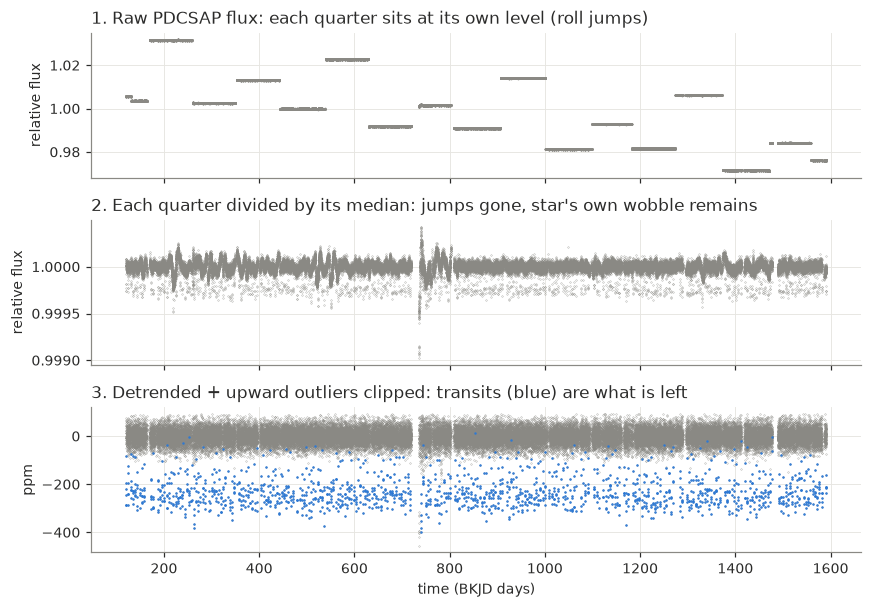

In [10]:
quarters = download_quarters(planet.kepid)
raw_t = np.concatenate([q[0][q[2] == 0] for q in quarters])
raw_f = np.concatenate([q[1][q[2] == 0] for q in quarters])
ok = np.isfinite(raw_f) & np.isfinite(raw_t)
st_t, st_f = stitch_quarters(quarters)
t_p, f_p = clean_light_curve(quarters, planet.koi_period, planet.koi_time0bk, planet.koi_duration)

fig, ax = plt.subplots(3, 1, figsize=(8, 5.6), sharex=True)
ax[0].plot(raw_t[ok], raw_f[ok] / np.nanmedian(raw_f), ".", ms=0.4, color=GREY)
ax[0].set_title("1. Raw PDCSAP flux: each quarter sits at its own level (roll jumps)", loc="left")
ax[1].plot(st_t, st_f, ".", ms=0.4, color=GREY)
ax[1].set_title("2. Each quarter divided by its median: jumps gone, star's own wobble remains", loc="left")
ax[2].plot(t_p, (f_p - 1) * 1e6, ".", ms=0.4, color=GREY)
intr = np.abs(phase_time(t_p, planet.koi_period, planet.koi_time0bk)) < planet.koi_duration / 48
ax[2].plot(t_p[intr], (f_p[intr] - 1) * 1e6, ".", ms=1.2, color=BLUE)
ax[2].set_title("3. Detrended + upward outliers clipped: transits (blue) are what is left", loc="left")
ax[2].set(ylabel="ppm", xlabel="time (BKJD days)")
for a in ax[:2]:
    a.set_ylabel("relative flux")
save(fig, "cleaning.png")

**The √N argument, measured.** Fold only the first N transits and measure the signal-to-noise of the folded
dip. If the noise is independent from point to point, it should grow like √N.

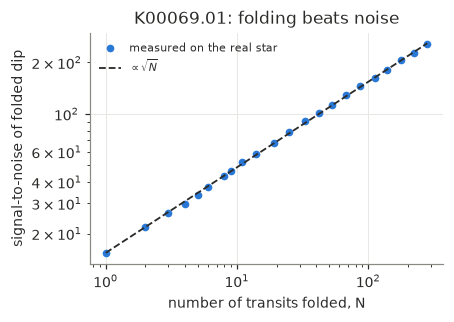

In [11]:
P, t0, dur = planet.koi_period, planet.koi_time0bk, planet.koi_duration / 24
epoch = np.round((t_p - t0) / P)
x = phase_time(t_p, P, t0)
noise = np.std(f_p[np.abs(x) > 2 * dur])
Ns, snr = [], []
for N in np.unique(np.geomspace(1, epoch.max() - epoch.min() + 1, 25).astype(int)):
    inside = (epoch < epoch.min() + N) & (np.abs(x) < 0.3 * dur)
    if inside.sum() < 3:
        continue
    Ns.append(len(np.unique(epoch[inside])))
    snr.append((1 - f_p[inside].mean()) / (noise / np.sqrt(inside.sum())))
Ns, snr = np.array(Ns), np.array(snr)

fig, ax = plt.subplots(figsize=(4.2, 3.0))
ax.plot(Ns, snr, "o", ms=4, color=BLUE, label="measured on the real star")
nn_ = np.linspace(1, Ns.max(), 100)
ax.plot(nn_, np.median(snr / np.sqrt(Ns)) * np.sqrt(nn_), color=INK, lw=1.2, ls="--", label=r"$\propto\sqrt{N}$")
ax.set(xscale="log", yscale="log", xlabel="number of transits folded, N",
       ylabel="signal-to-noise of folded dip", title=f"{planet.kepoi_name}: folding beats noise")
ax.legend(fontsize=7)
save(fig)

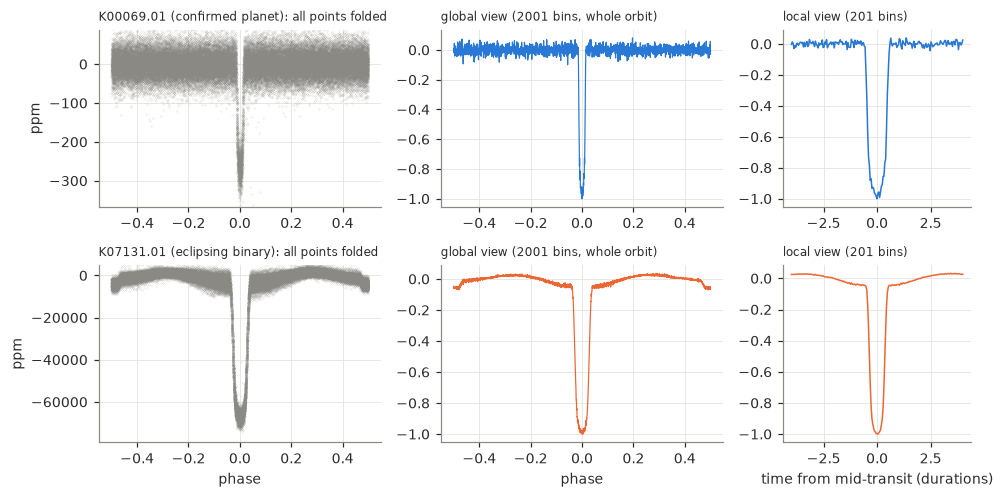

In [12]:
t_e, f_e = clean_light_curve(download_quarters(eb.kepid), eb.koi_period, eb.koi_time0bk, eb.koi_duration)
examples = [(planet, t_p, f_p, "confirmed planet", BLUE), (eb, t_e, f_e, "eclipsing binary", ORANGE)]

fig, ax = plt.subplots(2, 3, figsize=(9, 4.6), gridspec_kw={"width_ratios": [1.2, 1.2, 0.8]})
for i, (row, t, f, label, c) in enumerate(examples):
    k = np.where(table.kepoi_name == row.kepoi_name)[0][0]
    x = phase_time(t, row.koi_period, row.koi_time0bk)
    ax[i, 0].plot(x / row.koi_period, (f - 1) * 1e6, ".", ms=0.3, color=GREY, alpha=0.5)
    lo, hi = np.percentile((f - 1) * 1e6, [0.05, 99.9])
    ax[i, 0].set_ylim(lo * 1.1, hi)
    ax[i, 0].set_ylabel("ppm")
    ax[i, 0].set_title(f"{row.kepoi_name} ({label}): all points folded", loc="left", fontsize=8)
    ax[i, 1].plot(np.linspace(-0.5, 0.5, GLOBAL_BINS), G[k], color=c, lw=0.8)
    ax[i, 1].set_title("global view (2001 bins, whole orbit)", loc="left", fontsize=8)
    ax[i, 2].plot(np.linspace(-4, 4, LOCAL_BINS), L[k], color=c, lw=1.0)
    ax[i, 2].set_title("local view (201 bins)", loc="left", fontsize=8)
ax[1, 0].set_xlabel("phase")
ax[1, 1].set_xlabel("phase")
ax[1, 2].set_xlabel("time from mid-transit (durations)")
save(fig, "views.png")

## 7. The network

    global view (2001) -> [conv-relu-pool] x4 --\
                                                 concat -> dense(64) -> relu -> dropout -> dense(1) = logit
    local view  (201)  -> [conv-relu-pool] x2 --/

Every block is Conv1d (kernel 5, 'same' padding) → ReLU → MaxPool(2).

In [13]:
def block(c_in, c_out):
    return nn.Sequential(
        nn.Conv1d(c_in, c_out, kernel_size=5, padding=2),   # length unchanged
        nn.ReLU(),
        nn.MaxPool1d(2),                                     # length halves
    )


class AstroNet(nn.Module):
    def __init__(self, dropout=0.3):
        super().__init__()
        # global branch: 2001 -> 1000 -> 500 -> 250 -> 125 points
        self.global_branch = nn.Sequential(block(1, 16), block(16, 16), block(16, 32), block(32, 32))
        # local branch: 201 -> 100 -> 50 points
        self.local_branch = nn.Sequential(block(1, 16), block(16, 32))
        self.head = nn.Sequential(
            nn.Linear(32 * 125 + 32 * 50, 64),   # 4000 + 1600 = 5600 features in
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, 1),                    # one number: the logit
        )

    def forward(self, g, l):
        # g: (batch, 2001), l: (batch, 201)  ->  add a channel axis for Conv1d
        g = self.global_branch(g.unsqueeze(1)).flatten(1)    # (batch, 4000)
        l = self.local_branch(l.unsqueeze(1)).flatten(1)     # (batch, 1600)
        return self.head(torch.cat([g, l], dim=1)).squeeze(1)


print(f"trainable parameters: {sum(p.numel() for p in AstroNet().parameters()):,}")

trainable parameters: 370,353


## 8. Training

CONFIRMED (y = 1) vs FALSE POSITIVE (y = 0). The split is 70% train / 15% validation / 15% test, done **by
star**: a star with two planets goes entirely into one split, otherwise the network could learn the star's
noise in training and get an unfair hint at test time. We keep the weights with the best validation loss and
stop after 12 epochs without improvement.

In [14]:
SEED = 42
EPOCHS = 60
BATCH = 64
LEARNING_RATE = 1e-3
PATIENCE = 12          # stop if validation loss hasn't improved for this many epochs

labelled = table.koi_disposition.isin(["CONFIRMED", "FALSE POSITIVE"]).to_numpy()
G_lab, L_lab = G[labelled], L[labelled]
lab_table = table[labelled].reset_index(drop=True)
y = (lab_table.koi_disposition == "CONFIRMED").to_numpy().astype(np.float32)


def split_by_star(table):
    groups = table.kepid.to_numpy()
    idx = np.arange(len(table))
    train, rest = next(GroupShuffleSplit(1, test_size=0.30, random_state=SEED).split(idx, groups=groups))
    v, t = next(GroupShuffleSplit(1, test_size=0.50, random_state=SEED).split(rest, groups=groups[rest]))
    return train, rest[v], rest[t]


def predict(model, g, l):
    model.eval()
    with torch.no_grad():
        return torch.sigmoid(model(torch.from_numpy(g), torch.from_numpy(l))).numpy()


tr, va, te = split_by_star(lab_table)
print(f"train {len(tr)}  val {len(va)}  test {len(te)}   planet fraction in train: {y[tr].mean():.2f}")

train 1090  val 246  test 238   planet fraction in train: 0.50


In [15]:
torch.manual_seed(SEED)
np.random.seed(SEED)

model = AstroNet()
opt = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
loss_fn = nn.BCEWithLogitsLoss()       # sigmoid + binary cross-entropy in one, numerically stable

Gt, Lt, yt = map(torch.from_numpy, (G_lab[tr], L_lab[tr], y[tr]))
best, best_state, wait, history = np.inf, None, 0, []

for epoch in range(1, EPOCHS + 1):
    model.train()
    perm = torch.randperm(len(tr))
    total = 0.0
    for i in range(0, len(tr), BATCH):
        b = perm[i:i + BATCH]
        g, l, yb = Gt[b], Lt[b], yt[b]
        # augmentation: a transit looks the same played backwards in time,
        # so flipping half the batch left-right is a free extra example
        flip = torch.rand(len(b)) < 0.5
        g = torch.where(flip[:, None], g.flip(1), g)
        l = torch.where(flip[:, None], l.flip(1), l)

        opt.zero_grad()
        loss = loss_fn(model(g, l), yb)
        loss.backward()                 # backprop: dL/dw for every weight
        opt.step()                      # Adam update
        total += loss.item() * len(b)

    p_val = predict(model, G_lab[va], L_lab[va])
    val_loss = nn.functional.binary_cross_entropy(
        torch.from_numpy(p_val).clamp(1e-6, 1 - 1e-6), torch.from_numpy(y[va])).item()
    val_auc = roc_auc_score(y[va], p_val)
    history.append(dict(epoch=epoch, train_loss=total / len(tr), val_loss=val_loss, val_auc=val_auc))
    print(f"epoch {epoch:3d}  train loss {total / len(tr):.4f}  val loss {val_loss:.4f}  val AUC {val_auc:.4f}")

    if val_loss < best:
        best, wait = val_loss, 0
        best_state = {k: v.clone() for k, v in model.state_dict().items()}
    else:
        wait += 1
        if wait >= PATIENCE:
            print("early stopping")
            break

model.load_state_dict(best_state)
torch.save(best_state, os.path.join(RESULTS, "model.pt"))
history = pd.DataFrame(history)
history.to_csv(os.path.join(RESULTS, "history.csv"), index=False)
best_epoch = int(history.val_loss.idxmin() + 1)

epoch   1  train loss 0.6951  val loss 0.6838  val AUC 0.6921


epoch   2  train loss 0.6678  val loss 0.6350  val AUC 0.8483


epoch   3  train loss 0.5826  val loss 0.5289  val AUC 0.9253


epoch   4  train loss 0.4809  val loss 0.4517  val AUC 0.9411


epoch   5  train loss 0.4411  val loss 0.4256  val AUC 0.9540


epoch   6  train loss 0.4605  val loss 0.3738  val AUC 0.9659


... (35 outputs left out)

epoch  42  train loss 0.1491  val loss 0.1956  val AUC 0.9860


epoch  43  train loss 0.1647  val loss 0.1925  val AUC 0.9858


epoch  44  train loss 0.1577  val loss 0.1919  val AUC 0.9854


epoch  45  train loss 0.1424  val loss 0.2025  val AUC 0.9815
early stopping


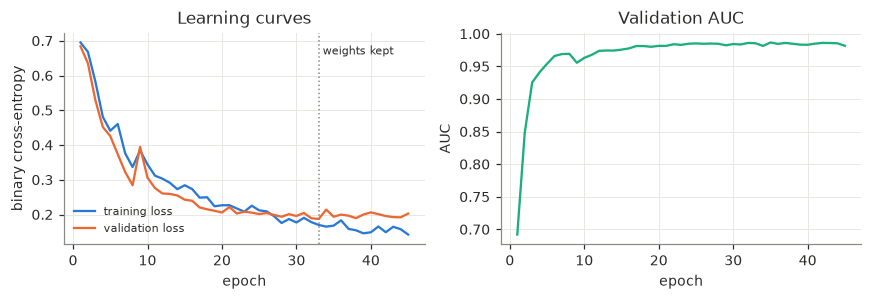

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(8, 2.8))
ax[0].plot(history.epoch, history.train_loss, color=BLUE, label="training loss")
ax[0].plot(history.epoch, history.val_loss, color=ORANGE, label="validation loss")
ax[0].axvline(best_epoch, color=GREY, ls=":", lw=1)
ax[0].text(best_epoch, ax[0].get_ylim()[1] * 0.95, " weights kept", fontsize=7, va="top")
ax[0].set(xlabel="epoch", ylabel="binary cross-entropy", title="Learning curves")
ax[0].legend(fontsize=7)
ax[1].plot(history.epoch, history.val_auc, color=AQUA)
ax[1].set(xlabel="epoch", ylabel="AUC", title="Validation AUC")
save(fig, "training.png")

## 9. Results on the test set

The test set is touched exactly once, here. We compare against two references:

* **logistic regression** on the same two views: what our CNN would collapse into without convolutions and ReLU
* **NASA's koi_score**, on the test KOIs that have one (it uses far more information than the light curve shape)

In [17]:
def scores(y, p, thr=0.5):
    yhat = (p >= thr).astype(int)
    return dict(accuracy=accuracy_score(y, yhat), precision=precision_score(y, yhat),
                recall=recall_score(y, yhat), f1=f1_score(y, yhat),
                auc=roc_auc_score(y, p), avg_precision=average_precision_score(y, p),
                confusion=confusion_matrix(y, yhat).tolist())


p_test = predict(model, G_lab[te], L_lab[te])
metrics = {"n_train": len(tr), "n_val": len(va), "n_test": len(te),
           "epochs_run": len(history), "best_epoch": best_epoch, "cnn": scores(y[te], p_test)}

# baseline: plain logistic regression on the same two views, no convolutions
X = np.hstack([G_lab, L_lab])
logreg = LogisticRegression(C=0.1, max_iter=3000).fit(X[tr], y[tr])
metrics["logreg"] = scores(y[te], logreg.predict_proba(X[te])[:, 1])

# NASA's own pipeline score (a few KOIs have none, so both are compared on the ones that do)
ks = lab_table.koi_score.to_numpy()[te]
has = np.isfinite(ks)
metrics["koi_score"] = scores(y[te][has], ks[has])
metrics["cnn_on_scored"] = scores(y[te][has], p_test[has])
metrics["n_scored"] = int(has.sum())

test_pred = lab_table.iloc[te][["kepid", "kepoi_name", "koi_disposition", "koi_score",
                                "koi_period", "koi_depth", "koi_model_snr"]].copy()
test_pred["y"] = y[te]
test_pred["p_cnn"] = p_test
test_pred.to_csv(os.path.join(RESULTS, "test_predictions.csv"), index=False)
json.dump(metrics, open(os.path.join(RESULTS, "metrics.json"), "w"), indent=2)

pd.DataFrame({name: {k: metrics[key][k] for k in ("accuracy", "precision", "recall", "f1", "auc")}
              for name, key in [("our CNN", "cnn"), ("logistic regression", "logreg"),
                                ("our CNN (scored KOIs)", "cnn_on_scored"),
                                ("NASA koi_score", "koi_score")]}).T.round(3)

,accuracy,precision,recall,f1,auc
our CNN,0.887,0.871,0.908,0.889,0.963
logistic regression,0.811,0.789,0.849,0.818,0.882
our CNN (scored KOIs),0.896,0.893,0.923,0.908,0.968
NASA koi_score,0.976,0.983,0.974,0.979,0.992


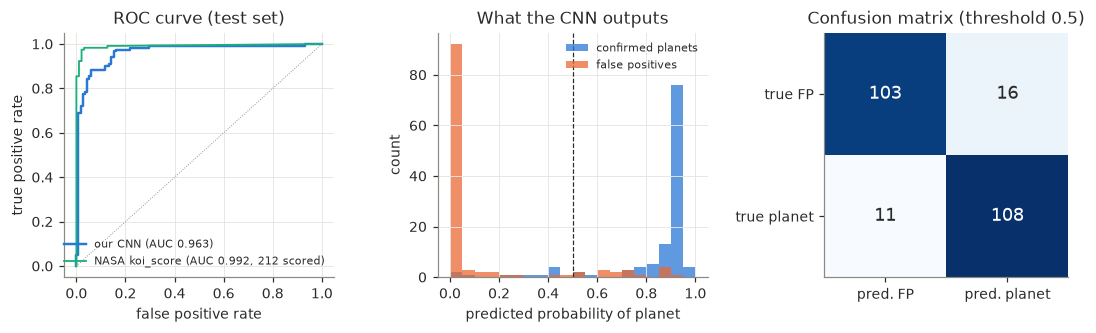

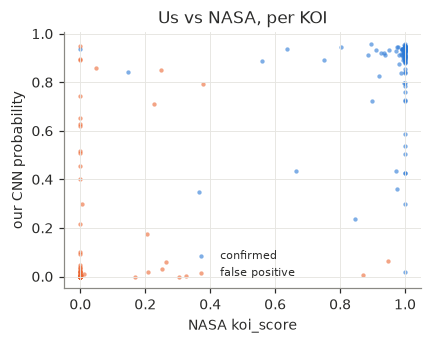

In [18]:
p = test_pred
fig, ax = plt.subplots(1, 3, figsize=(10, 3.1))
fpr, tpr, _ = roc_curve(p.y, p.p_cnn)
ax[0].plot(fpr, tpr, color=BLUE, lw=1.6, label=f"our CNN (AUC {metrics['cnn']['auc']:.3f})")
s = p[np.isfinite(p.koi_score)]
f2, t2, _ = roc_curve(s.y, s.koi_score)
ax[0].plot(f2, t2, color=AQUA, lw=1.2,
           label=f"NASA koi_score (AUC {metrics['koi_score']['auc']:.3f}, {len(s)} scored)")
ax[0].plot([0, 1], [0, 1], color=GREY, lw=0.6, ls=":")
ax[0].set(xlabel="false positive rate", ylabel="true positive rate", title="ROC curve (test set)")
ax[0].legend(fontsize=7, loc="lower right")

bins = np.linspace(0, 1, 21)
ax[1].hist(p.p_cnn[p.y == 1], bins, color=BLUE, alpha=0.75, label="confirmed planets")
ax[1].hist(p.p_cnn[p.y == 0], bins, color=ORANGE, alpha=0.75, label="false positives")
ax[1].axvline(0.5, color=INK, lw=0.8, ls="--")
ax[1].set(xlabel="predicted probability of planet", ylabel="count", title="What the CNN outputs")
ax[1].legend(fontsize=7)

cm = np.array(metrics["cnn"]["confusion"])
ax[2].imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax[2].text(j, i, cm[i, j], ha="center", va="center",
                   color="white" if cm[i, j] > cm.max() / 2 else INK, fontsize=12)
ax[2].set_xticks([0, 1], ["pred. FP", "pred. planet"])
ax[2].set_yticks([0, 1], ["true FP", "true planet"])
ax[2].grid(False)
ax[2].set_title("Confusion matrix (threshold 0.5)")
save(fig, "evaluation.png")

fig, ax = plt.subplots(figsize=(4, 3.2))
for label, c, name in [(1, BLUE, "confirmed"), (0, ORANGE, "false positive")]:
    s = p[p.y == label]
    ax.scatter(s.koi_score, s.p_cnn, s=8, color=c, alpha=0.6, label=name, linewidths=0)
ax.set(xlabel="NASA koi_score", ylabel="our CNN probability", title="Us vs NASA, per KOI")
ax.legend(fontsize=7)
save(fig, "vs_koiscore.png")

### Where it goes wrong

Errors split by signal-to-noise, and the four test KOIs the CNN got most confidently wrong.

error rate, SNR < 20:  20.6%  (68 KOIs)
error rate, SNR >= 20: 6.8%  (162 KOIs)


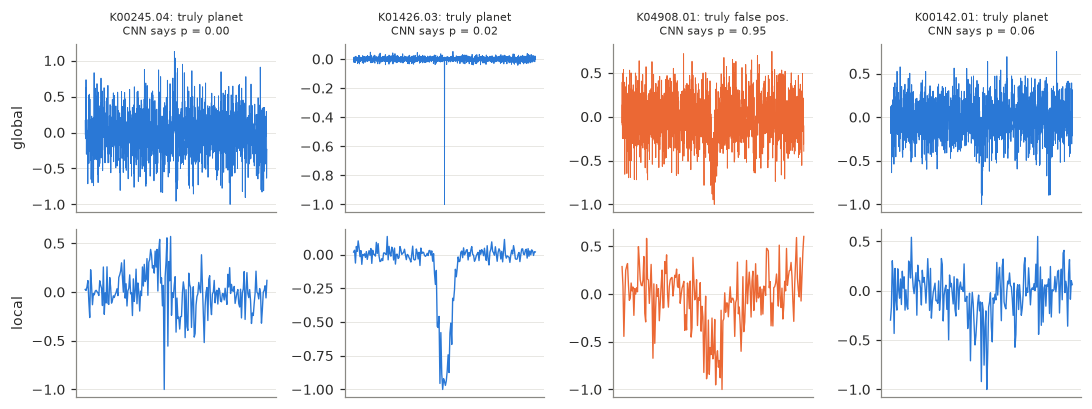

In [19]:
wrong = (p.p_cnn >= 0.5) != (p.y == 1)
print(f"error rate, SNR < 20:  {wrong[p.koi_model_snr < 20].mean():.1%}  ({(p.koi_model_snr < 20).sum()} KOIs)")
print(f"error rate, SNR >= 20: {wrong[p.koi_model_snr >= 20].mean():.1%}  ({(p.koi_model_snr >= 20).sum()} KOIs)")

worst = p.assign(err=np.abs(p.y - p.p_cnn)).sort_values("err", ascending=False).head(4)
fig, ax = plt.subplots(2, 4, figsize=(10, 3.8))
for j, r in enumerate(worst.itertuples()):
    k = np.where(table.kepoi_name == r.kepoi_name)[0][0]
    c = BLUE if r.y == 1 else ORANGE
    ax[0, j].plot(G[k], color=c, lw=0.6)
    ax[1, j].plot(L[k], color=c, lw=0.9)
    truth = "planet" if r.y == 1 else "false pos."
    ax[0, j].set_title(f"{r.kepoi_name}: truly {truth}\nCNN says p = {r.p_cnn:.2f}", fontsize=7.5)
    for a in ax[:, j]:
        a.set_xticks([])
ax[0, 0].set_ylabel("global")
ax[1, 0].set_ylabel("local")
save(fig, "mistakes.png")

**What did the first layer learn?** The 16 five-weight kernels of the first global-branch convolution.
Orange kernels have weights summing to less than zero.

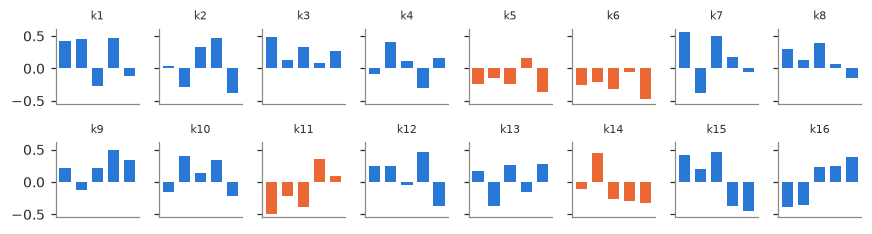

In [20]:
w = model.global_branch[0][0].weight.detach().numpy()[:, 0, :]   # (16, 5)
fig, ax = plt.subplots(2, 8, figsize=(8, 2.2), sharey=True)
for k, a in enumerate(ax.flat):
    a.bar(range(5), w[k], color=BLUE if w[k].sum() >= 0 else ORANGE, width=0.7)
    a.set_xticks([])
    a.set_title(f"k{k + 1}", fontsize=7)
    a.grid(False)
save(fig)

### Kepler-88 b: when folding fails

K00142.01 is a real planet with SNR above 300, yet the CNN rejects it. We measure the time of every single
transit and compare it with the strictly periodic prediction t0 + nP ("observed minus calculated", O − C).
Folding assumes O − C = 0; a second planet tugging on Kepler-88 b makes its transits wander instead.

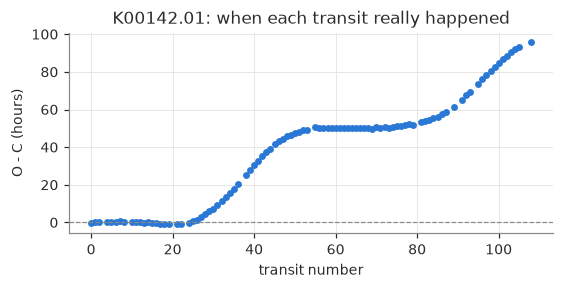

transit times wander by 4.0 days


In [21]:
def transit_timing(name):
    k = koi.set_index("kepoi_name").loc[name]
    t, f = stitch_quarters(download_quarters(int(k.kepid)))
    trend = pd.Series(f, index=pd.to_timedelta(t, unit="D")).rolling(
        pd.Timedelta(days=2), center=True, min_periods=10).median().to_numpy()
    f = f / trend - 1
    P, t0, T, depth = k.koi_period, k.koi_time0bk, k.koi_duration / 24, k.koi_depth / 1e6
    shifts = np.arange(-4, 4, 0.005)
    epochs, oc = [], []
    for e in range(int((t.max() - t0) / P) + 1):
        tc = t0 + e * P
        near = np.abs(t - tc) < 4.5
        if near.sum() < 100:
            continue
        tt, ff = t[near] - tc, f[near]
        # slide a box of the transit's duration; where is the mean flux lowest?
        box = [ff[np.abs(tt - s) < T / 2].mean() if (np.abs(tt - s) < T / 2).sum() > 3 else 0
               for s in shifts]
        i = int(np.argmin(box))
        if box[i] < -0.5 * depth:
            epochs.append(e)
            oc.append(shifts[i] * 24)
    return epochs, oc


epochs, oc = transit_timing("K00142.01")
ttv_range_hours = float(max(oc) - min(oc))
fig, ax = plt.subplots(figsize=(5.2, 2.7))
ax.plot(epochs, oc, "o", ms=3.5, color=BLUE)
ax.axhline(0, color=GREY, lw=0.8, ls="--")
ax.set(xlabel="transit number", ylabel="O - C (hours)", title="K00142.01: when each transit really happened")
save(fig, "ttv.png")
print(f"transit times wander by {ttv_range_hours / 24:.1f} days")

## 10. The unconfirmed candidates

Finally, predictions for the CANDIDATE KOIs nobody has decided on yet. For the ones the CNN likes, the
catalogue's stellar parameters turn the dip into a physical picture:

* radius from depth: R<sub>p</sub> = R<sub>*</sub>√δ
* orbit from Kepler's third law (solar units): a = (M<sub>*</sub> P²)<sup>1/3</sup> AU
* equilibrium temperature (zero albedo): T<sub>eq</sub> = T<sub>eff</sub>√(R<sub>*</sub> / 2a)

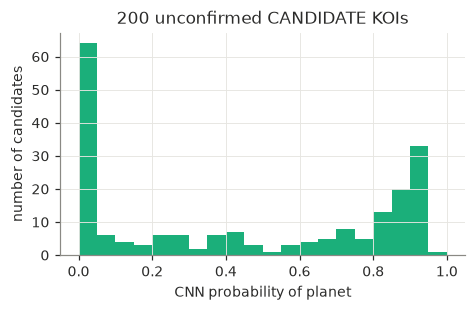

,kepoi_name,p_cnn,koi_score,koi_period,rp_earth,a_au,teq_k
1460,K04892.01,0.957,0.526,21.376,1.170,0.143,783.838
517,K05249.01,0.949,0.954,19.453,1.352,0.145,814.047
579,K02093.01,0.944,0.999,6.783,21.418,0.064,2874.528
1769,K04714.01,0.944,1.000,2.050,1.161,0.030,1313.240
415,K03377.01,0.940,1.000,10.010,1.074,0.072,553.784
99,K03340.02,0.938,0.999,13.728,1.067,0.109,875.368
1501,K03451.01,0.934,1.000,10.908,1.707,0.101,1044.447
465,K02377.01,0.934,0.893,13.903,1.445,0.106,705.881


In [22]:
def physics(df):
    rp = df.koi_srad * np.sqrt(df.koi_depth / 1e6) * 109.1         # Earth radii
    a = (df.koi_smass * (df.koi_period / 365.25) ** 2) ** (1 / 3)   # AU
    teq = df.koi_steff * np.sqrt(df.koi_srad / (2 * a * 215.03))    # 1 AU = 215 solar radii
    return rp, a, teq


is_cand = (table.koi_disposition == "CANDIDATE").to_numpy()
cand = table[is_cand].copy()
cand["p_cnn"] = predict(model, G[is_cand], L[is_cand])
cand["rp_earth"], cand["a_au"], cand["teq_k"] = physics(cand)
cand = cand.sort_values("p_cnn", ascending=False)
cand[["kepoi_name", "p_cnn", "koi_score", "koi_period", "koi_depth", "rp_earth", "koi_prad", "a_au",
      "teq_k"]].to_csv(os.path.join(RESULTS, "candidate_predictions.csv"), index=False)

fig, ax = plt.subplots(figsize=(4.4, 2.9))
ax.hist(cand.p_cnn, np.linspace(0, 1, 21), color=AQUA)
ax.set(xlabel="CNN probability of planet", ylabel="number of candidates",
       title=f"{len(cand)} unconfirmed CANDIDATE KOIs")
save(fig, "candidates.png")

cand.head(8)[["kepoi_name", "p_cnn", "koi_score", "koi_period", "rp_earth", "a_au", "teq_k"]].round(3)

In [23]:
# the few numbers the report quotes that aren't in the files above
analysis = dict(example_planet=planet.kepoi_name, example_eb=eb.kepoi_name,
                cand_above_09=int((cand.p_cnn > 0.9).sum()), cand_below_01=int((cand.p_cnn < 0.1).sum()),
                ttv_range_hours=ttv_range_hours,
                worst=worst[["kepoi_name", "y", "p_cnn", "koi_period", "koi_depth"]].to_dict("records"))
json.dump(analysis, open(os.path.join(RESULTS, "analysis.json"), "w"), indent=2, default=float)
print("Done.")

Done.
